In [1]:
from IPython.display import Image
import matplotlib.pyplot as plt
import scipy.stats
import numpy as np
import pandas as pd
import openmc
%matplotlib inline
import openmc.deplete
import glob
import os 
import openmc_data_downloader as odd
# openmc.config['cross_sections']='/home/user/endfb-viii.0-hdf5/cross_sections.xml'
openmc.config['chain_file']='/home/nuclear1/Downloads/R_Depletion/chain_casl_sfr.xml'
import math

In [2]:
#material composition

#fuel composition
PuO2 = openmc.Material(material_id=1, name = 'Plutonium Dioxide')
PuO2.add_nuclide('Pu238', 0.01)
PuO2.add_nuclide('Pu239', 0.659)
PuO2.add_nuclide('Pu240', 0.252)
PuO2.add_nuclide('Pu241', 0.039)
PuO2.add_nuclide('Pu242', 0.04)
PuO2.add_nuclide('O16', 2.0)
PuO2.set_density('g/cm3', 10.887)

UO2_dep = openmc.Material(material_id=2, name = 'Depleted Uranium') # Depleted uranium dioxide
UO2_dep.add_element('U', 1, enrichment = 0.25)
UO2_dep.add_element('O', 2.0)
UO2_dep.set_density('g/cc', 11.08)
#UO2_dep.temperature = 1200

# Minor actinide (MA) composition

MA = openmc.Material(material_id=3,name = 'Minor Actinides')
MA.add_nuclide('Np237', 0.562, 'wo')
MA.add_nuclide('Am241', 0.264, 'wo')
MA.add_nuclide('Am243', 0.12, 'wo')
MA.add_nuclide('Cm243', 0.0003, 'wo')
MA.add_nuclide('Cm244', 0.0511, 'wo')
MA.add_nuclide('Cm245', 0.0026, 'wo')
MA.set_density('g/cm3', 15.43)

# --- computed mass fractions  ---
MOX1 = openmc.Material.mix_materials([UO2_dep, PuO2, MA],
    [0.772058487165646, 0.2097061918076057, 0.01823532102674831], 'wo')
MOX1.name = "MOX_inner (21.7 at% Pu+Am241)"
MOX1.id = 4

MOX2 = openmc.Material.mix_materials([UO2_dep, PuO2, MA],
    [0.7091255190889936, 0.267604522438126, 0.023269958472880506], 'wo')
MOX2.name = "MOX_outer (27.8 at% Pu+Am241)"
MOX2.id = 5

# Gas gap composition
helium = openmc.Material(material_id=6, name='Helium')
helium.set_density('g/cm3', 0.001598)
helium.add_element('He', 1,'wo')
helium.temperature = 1200
helium.depletable = False

# Clad composition
t91 = openmc.Material(material_id=7, name='clad material')
t91.set_density('g/cm3', 7.7)
t91.add_element('Fe', 0.884, 'wo')
t91.add_element('Cr', 0.09, 'wo')
t91.add_element('Mo', 0.01  , 'wo')
t91.add_element('Mn', 0.006, 'wo')
t91.add_element('Si', 0.005, 'wo')
t91.add_element('V', 0.002, 'wo')
t91.add_element('Ni', 0.002, 'wo')
t91.add_element('Nb', 0.001, 'wo')
t91.temperature= 900
t91.depletable = False
#t91.temperature = 900 # The maximum clad temperature at normal operating conditions is 550°C or 823 K.

# Coolant composition 
lead = openmc.Material(material_id=8, name='Lead Coolant')
lead.add_element('Pb', 1)
lead.set_density('g/cm3', 10.58)
lead.temperature = 600 # The core inlet temperature is 400°C.
lead.depletable=False

# Absorber material
b4c = openmc.Material(material_id=9, name='Boron Carbide Absorber')
b4c.add_element('B', 4, enrichment = 90.0, enrichment_target = 'B10')
b4c.add_element('C', 1)
b4c.set_density('g/cm3', 2.52)
b4c.temperature = 600
b4c.depletable = False

#reflector material
reflector = openmc.Material(material_id=10, name='Zirconium Silicate (Zr3Si2)')
reflector.set_density('g/cm3', 5.88)  # density at ~600 K
reflector.add_element('Zr', 3)      
reflector.add_element('Si', 2)
reflector.temperature=600

MOX1.temperature= 1200
MOX2.temperature= 1200
print(MOX1)
print(MOX2)

Material
	ID             =	4
	Name           =	MOX_inner (21.7 at% Pu+Am241)
	Temperature    =	1200
	Density        =	11.09579254506646 [g/cm3]
	Volume         =	None [cm^3]
	Depletable     =	True
	S(a,b) Tables  
	Nuclides       
	U234           =	5.897654155507195e-06 [ao]
	U235           =	0.0006598300816371616 [ao]
	U238           =	0.2599379726949998 [ao]
	U236           =	3.022338700845533e-06 [ao]
	O16            =	0.6607935114020442 [ao]
	O17            =	0.00019753989585927594 [ao]
	O18            =	0.0010426353764561888 [ao]
	Pu238          =	0.0007041012056768659 [ao]
	Pu239          =	0.04640026945410546 [ao]
	Pu240          =	0.01774335038305702 [ao]
	Pu241          =	0.0027459947021397767 [ao]
	Pu242          =	0.0028164048227074636 [ao]
	Np237          =	0.00394075391448551 [ao]
	Am241          =	0.0018203885724739587 [ao]
	Am243          =	0.000820625290040696 [ao]
	Cm243          =	2.0515631623043097e-06 [ao]
	Cm244          =	0.00034801583777755335 [ao]
	Cm245        

/home/nuclear1/anaconda3/envs/openmc_env/lib/python3.13/site-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=4.
  warn(msg, IDWarning)
/home/nuclear1/anaconda3/envs/openmc_env/lib/python3.13/site-packages/openmc/mixin.py:70: IDWarning: Another Material instance already exists with id=5.
  warn(msg, IDWarning)


In [3]:
# Instantiate a materials collection and export it to XML

materials_file = openmc.Materials([ MOX1, MOX2, helium, t91, lead, b4c, reflector])
materials_file.export_to_xml()
mat_colours= {t91:'black', helium:'skyblue', lead:'silver',
                      reflector:'magenta', MOX1:'blue', MOX2:'green', b4c:'cyan'}

In [4]:
odd.download_cross_section_data(
        materials_file,
        libraries=["ENDFB-8.0-NNDC"],
        set_OPENMC_CROSS_SECTIONS=True,
        particles=["neutron"],
    )

isotopes [np.str_('Am241'), np.str_('Am243'), 'B10', 'B11', 'C12', 'C13', np.str_('Cm243'), np.str_('Cm244'), np.str_('Cm245'), 'Cr50', 'Cr52', 'Cr53', 'Cr54', 'Fe54', 'Fe56', 'Fe57', 'Fe58', 'He3', 'He4', 'Mn55', 'Mo100', 'Mo92', 'Mo94', 'Mo95', 'Mo96', 'Mo97', 'Mo98', 'Nb93', 'Ni58', 'Ni60', 'Ni61', 'Ni62', 'Ni64', np.str_('Np237'), np.str_('O16'), np.str_('O17'), np.str_('O18'), 'Pb204', 'Pb206', 'Pb207', 'Pb208', np.str_('Pu238'), np.str_('Pu239'), np.str_('Pu240'), np.str_('Pu241'), np.str_('Pu242'), 'Si28', 'Si29', 'Si30', np.str_('U234'), np.str_('U235'), np.str_('U236'), np.str_('U238'), 'V50', 'V51', 'Zr90', 'Zr91', 'Zr92', 'Zr94', 'Zr96']
Searching libraries with the following priority {'ENDFB-8.0-NNDC': 1}
Isotopes found matching library requirements 556
Isotopes found matching particle requirements 1789
Isotopes found matching isotope requirements 224
Isotopes found matching all requirements 60
             library remote_file  \
1236  ENDFB-8.0-NNDC      He3.h5   
1388  EN

'/home/nuclear1/Downloads/R_Depletion/Dep_6/cross_sections.xml'

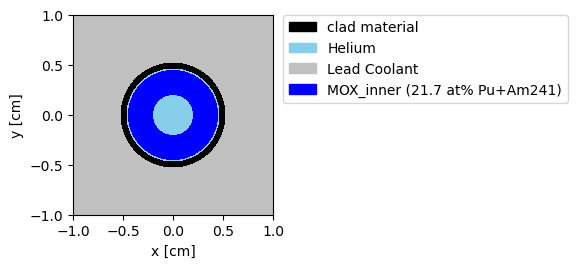

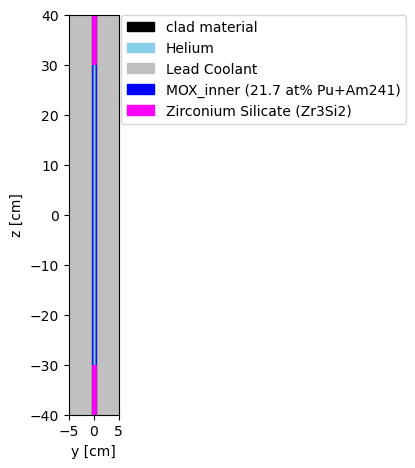

In [5]:
# fuel rod inner zone of the core

fuel_ir  = openmc.ZCylinder(r=0.20)
fuel_or  = openmc.ZCylinder(r=0.45)
clad_ir  = openmc.ZCylinder(r=0.465)
clad_or  = openmc.ZCylinder(r=0.525)

top_fuel      = openmc.ZPlane(z0=30, name='top')
bottom_fuel   = openmc.ZPlane(z0=-30, name='bottom')

top      = openmc.ZPlane(z0=40, name='top', boundary_type = 'reflective')
bottom   = openmc.ZPlane(z0=-40, name='bottom', boundary_type = 'reflective')


hole = openmc.Cell(name='Hole', region = -fuel_ir & -top_fuel & +bottom_fuel, fill = helium)
fuel_iz = openmc.Cell(name='Inner Zone Fuel', region  = +fuel_ir & -fuel_or & -top_fuel & +bottom_fuel, fill = MOX1) # iz refers to inner zone.
gap = openmc.Cell(name='Gap', region  = +fuel_or & -clad_ir & -top_fuel & +bottom_fuel, fill = helium)
clad = openmc.Cell(name='Cladding', region = +clad_ir & -clad_or& -top & +bottom, fill = t91)
bottom_reflector = openmc.Cell(name='Bottom Reflector', region = -clad_ir & +bottom & -bottom_fuel, fill = reflector)
top_reflector = openmc.Cell(name='Top Reflector', region = -clad_ir & +top_fuel & -top, fill = reflector)
coolant = openmc.Cell(name='Coolant', region = +clad_or, fill = lead)


f_iz = openmc.Universe(cells=[hole, fuel_iz, gap, clad, coolant, bottom_reflector, top_reflector])
f_iz.plot(width=(2.0,2.0), color_by = 'material', colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX1:'blue'}, legend=True)
f_iz.plot(basis='yz', width=(10,80), pixels= (400,400), color_by = 'material', colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX1:'blue', reflector:'magenta'}, legend=True)

# Instantiate coolant universe
lead_cell = openmc.Cell(fill=lead)
lead_univ = openmc.Universe(cells=[lead_cell])
 

/home/nuclear1/anaconda3/envs/openmc_env/lib/python3.13/site-packages/openmc/model/funcs.py:124: FutureWarning: The hexagonal_prism(...) function has been replaced by the HexagonalPrism(...) class. Future versions of OpenMC will not accept hexagonal_prism.
  warn("The hexagonal_prism(...) function has been replaced by the "


Text(0.5, 1.0, 'Inner Zone Assembly — YZ View')

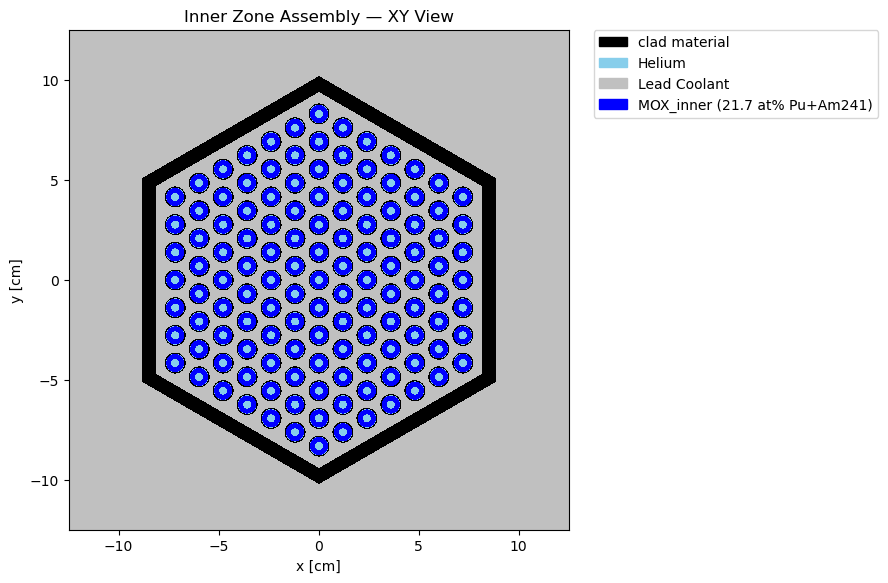

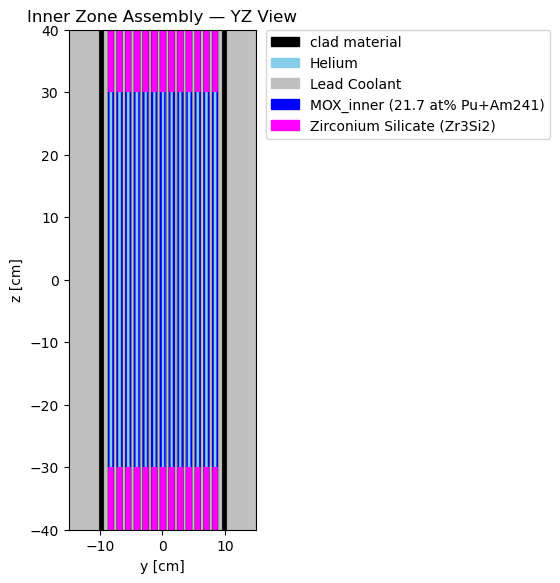

In [6]:
#Fuel assembly of inner zone

fa_iz = openmc.HexLattice()
fa_iz.center = (0., 0.)
fa_iz.pitch = (1.384,)
fa_iz.outer = lead_univ
fa_iz.orientation = 'y'

outer_ring = [f_iz]*36

ring_1 = [f_iz]*30

ring_2 = [f_iz]*24

ring_3 = [f_iz]*18

ring_4 = [f_iz]*12

ring_5 = [f_iz]*6

inner_ring = [f_iz]

fa_iz.universes = [outer_ring,  ring_1,  ring_2,  ring_3,  ring_4,  ring_5,  inner_ring]

# Create the prism that will contain the lattice
outer_in_surface = openmc.model.hexagonal_prism(edge_length=9.4, orientation='y')
wrapper_in_surface=openmc.model.hexagonal_prism(edge_length=10.2, orientation='y')
wrapper_cell=openmc.Cell(fill = t91, 
                    region= ~outer_in_surface & wrapper_in_surface & 
                    -top & +bottom)

# Fill a cell with the lattice. This cell is filled with the lattice and contained within the prism.
main_in_assembly = openmc.Cell(fill=fa_iz, region=outer_in_surface & -top & +bottom)

# Fill a cell with a material that will surround the lattice
out_in_assembly  = openmc.Cell(fill=lead, region=~wrapper_in_surface & -top & +bottom)

# Create a universe that contains both 
main_in_u = openmc.Universe(cells=[main_in_assembly, out_in_assembly,wrapper_cell])

# Plot the universe
main_in_u.plot(origin = (0,0,0), pixels=(500, 500), width = (25.,25.), color_by = 'material',
               colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX1:'blue'}, legend=True)
plt.title("Inner Zone Assembly — XY View")
main_in_u.plot(basis='yz', origin = (0,0,0), pixels=(500, 500), width = (30.,80.), color_by = 'material',
               colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX1:'blue', reflector:'magenta'}, legend=True)
plt.title("Inner Zone Assembly — YZ View")

<Axes: xlabel='y [cm]', ylabel='z [cm]'>

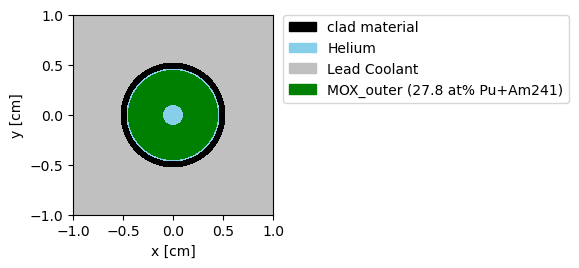

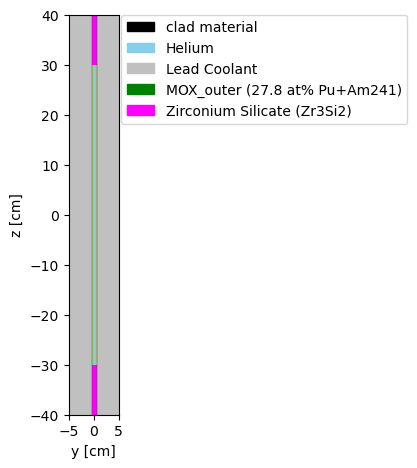

In [7]:
# Instantiate cylindrical surfaces (fuel of outer zone of the core)


fuel_ir  = openmc.ZCylinder(r=0.10)
fuel_or  = openmc.ZCylinder(r=0.45)
clad_ir  = openmc.ZCylinder(r=0.465)
clad_or  = openmc.ZCylinder(r=0.525)

top_fuel      = openmc.ZPlane(z0=30, name='top')
bottom_fuel   = openmc.ZPlane(z0=-30, name='bottom')

top      = openmc.ZPlane(z0=40, name='top', boundary_type = 'reflective')
bottom   = openmc.ZPlane(z0=-40, name='bottom', boundary_type = 'reflective')


hole = openmc.Cell(name='Hole', region = -fuel_ir & -top_fuel & +bottom_fuel, fill = helium)
fuel_oz = openmc.Cell(name='Inner Zone Fuel', region  = +fuel_ir & -fuel_or & -top_fuel & +bottom_fuel, fill = MOX2) # oz refers to outer zone.
gap = openmc.Cell(name='Gap', region  = +fuel_or & -clad_ir & -top_fuel & +bottom_fuel, fill = helium)
clad = openmc.Cell(name='Cladding', region = +clad_ir & -clad_or& -top & +bottom, fill = t91)
bottom_reflector = openmc.Cell(name='Bottom Reflector', region = -clad_ir & +bottom & -bottom_fuel, fill = reflector)
top_reflector = openmc.Cell(name='Top Reflector', region = -clad_ir & +top_fuel & -top, fill = reflector)
coolant = openmc.Cell(name='Coolant', region = +clad_or, fill = lead)


f_oz = openmc.Universe(cells=[hole, fuel_oz, gap, clad, coolant, bottom_reflector, top_reflector])
f_oz.plot(width=(2.0,2.0), color_by = 'material', colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX2:'green'}, legend=True)
f_iz.plot(basis='yz', width=(10,80), pixels= (400,400), color_by = 'material', colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX2:'green', reflector:'magenta'}, legend=True)


/home/nuclear1/anaconda3/envs/openmc_env/lib/python3.13/site-packages/openmc/model/funcs.py:124: FutureWarning: The hexagonal_prism(...) function has been replaced by the HexagonalPrism(...) class. Future versions of OpenMC will not accept hexagonal_prism.
  warn("The hexagonal_prism(...) function has been replaced by the "


Text(0.5, 1.0, 'Outer Zone Assembly — YZ View')

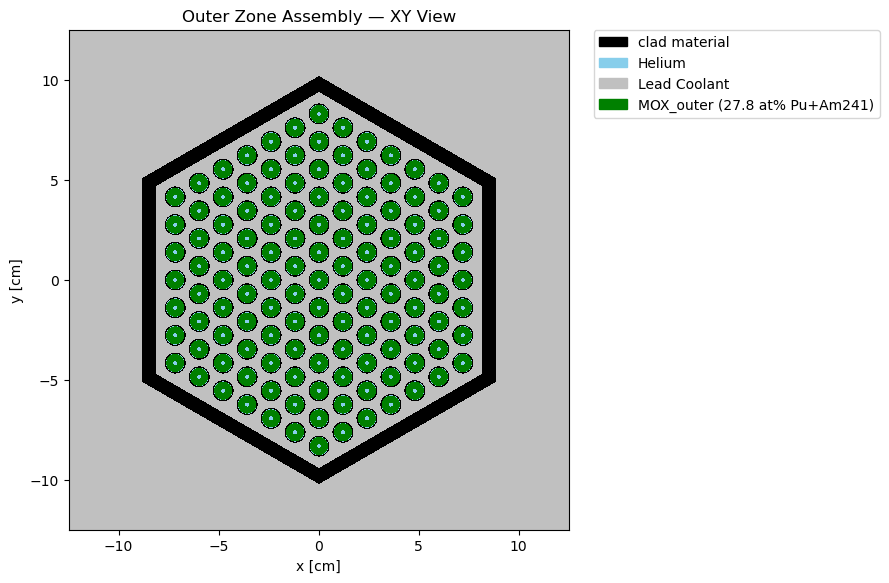

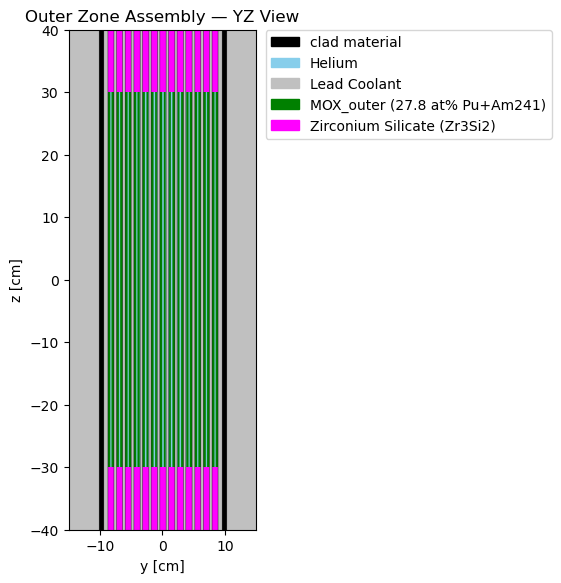

In [8]:
# Fuel assembly of the outer zone

fa_oz = openmc.HexLattice()
fa_oz.center = (0., 0.)
fa_oz.pitch = (1.384,)
fa_oz.outer = lead_univ
fa_oz.orientation = 'y'

outer_ring = [f_oz]*36

ring_1 = [f_oz]*30

ring_2 = [f_oz]*24

ring_3 = [f_oz]*18

ring_4 = [f_oz]*12

ring_5 = [f_oz]*6

inner_ring = [f_oz]

fa_oz.universes = [outer_ring, ring_1, ring_2, ring_3, ring_4, ring_5, inner_ring]

# Create the prism that will contain the lattice
outer_out_surface = openmc.model.hexagonal_prism(edge_length=9.4, orientation='y')
wrapper_out_surface=openmc.model.hexagonal_prism(edge_length=10.2, orientation='y')
wrapper_cell1=openmc.Cell(fill = t91, 
                    region= ~outer_out_surface & wrapper_out_surface & 
                    -top & +bottom)

# Fill a cell with the lattice. This cell is filled with the lattice and contained within the prism.
main_out_assembly = openmc.Cell(fill=fa_oz, region=outer_out_surface)

# Fill a cell with a material that will surround the lattice
out_out_assembly  = openmc.Cell(fill=lead, region=~wrapper_out_surface)

# Create a universe that contains both 
main_out_u = openmc.Universe(cells=[main_out_assembly, out_out_assembly, wrapper_cell1])

# Plot the universe
# Plot the universe
main_out_u.plot(origin = (0,0,0), pixels=(500, 500), width = (25.,25.), color_by = 'material',
               colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX2:'green'}, legend=True)
plt.title("Outer Zone Assembly — XY View")
main_out_u.plot(basis='yz', origin = (0,0,0), pixels=(500, 500), width = (30.,80.), color_by = 'material',
               colors = {t91:'black', helium:'skyblue', lead:'silver',
                       MOX2:'green', reflector:'magenta'}, legend=True)
plt.title("Outer Zone Assembly — YZ View")


<Axes: xlabel='y [cm]', ylabel='z [cm]'>

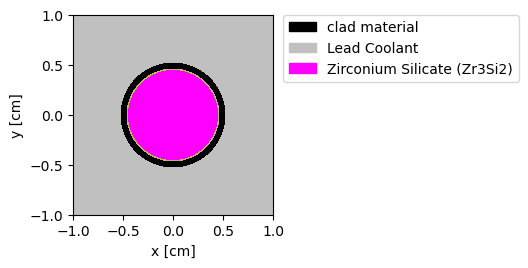

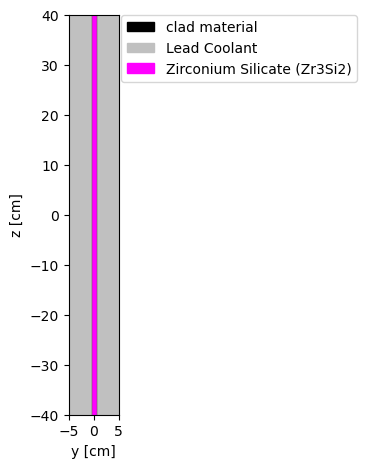

In [9]:
# Instantiate cylindrical surfaces (reflector zone)


fuel_or  = openmc.ZCylinder(r=0.45)
clad_ir  = openmc.ZCylinder(r=0.465)
clad_or  = openmc.ZCylinder(r=0.525)

top      = openmc.ZPlane(z0=40, name='top', boundary_type = 'reflective')
bottom   = openmc.ZPlane(z0=-40, name='bottom', boundary_type = 'reflective')


# Instantiate cells and fill with materials
ref = openmc.Cell(name='refletor cell', region  = -fuel_or & -top & +bottom, fill = reflector)
gap = openmc.Cell(name='Gap', region  = +fuel_or & -clad_ir& -top & +bottom, fill = helium)
clad = openmc.Cell(name='Cladding', region = +clad_ir & -clad_or& -top & +bottom, fill = t91)
coolant = openmc.Cell(name='Coolant', region = +clad_or, fill = lead)


# Instantiate reflector fuel universe
f_b = openmc.Universe(cells=[ref, gap, clad, coolant])
f_b.plot(width=(2.0,2.0), color_by = 'material',colors = {t91:'black', lead:'silver',
                        reflector:'magenta'}, legend=True)
f_b.plot(basis='yz', width=(10,80), pixels= (400,400), color_by = 'material', colors = {t91:'black', lead:'silver',
                       reflector:'magenta'}, legend=True)

/home/nuclear1/anaconda3/envs/openmc_env/lib/python3.13/site-packages/openmc/model/funcs.py:124: FutureWarning: The hexagonal_prism(...) function has been replaced by the HexagonalPrism(...) class. Future versions of OpenMC will not accept hexagonal_prism.
  warn("The hexagonal_prism(...) function has been replaced by the "


Text(0.5, 1.0, 'Reflector Assembly — YZ View')

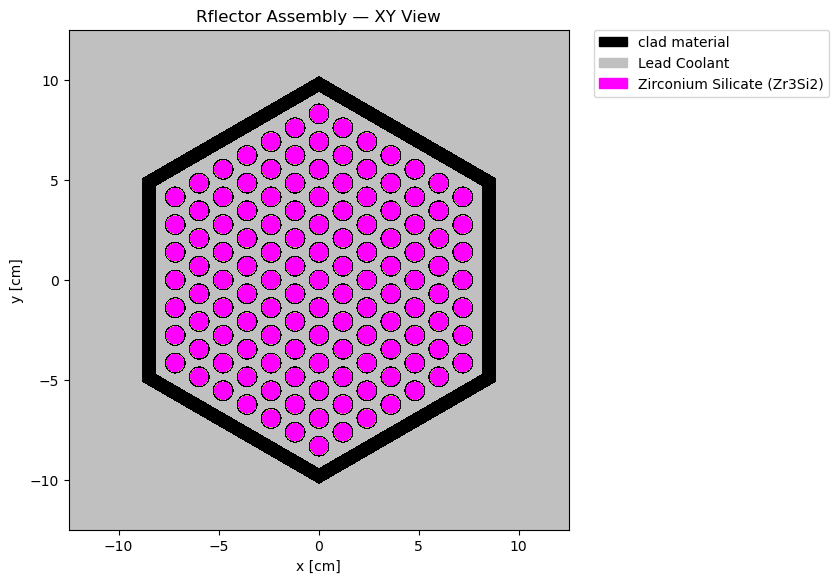

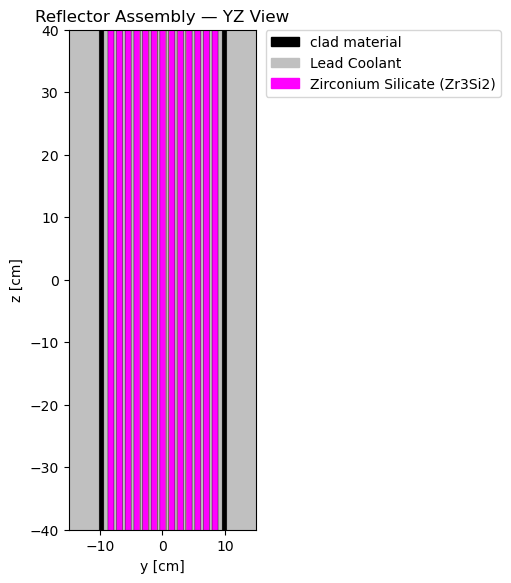

In [10]:
#reflector assembly 

ba = openmc.HexLattice()
ba.center = (0., 0.)
ba.pitch = (1.384,)
ba.outer = lead_univ
ba.orientation = 'y'

outer_ring = [f_b]*36

ring_1 = [f_b]*30

ring_2 = [f_b]*24

ring_3 = [f_b]*18

ring_4 = [f_b]*12

ring_5 = [f_b]*6

inner_ring = [f_b]

ba.universes = [outer_ring, ring_1, ring_2, ring_3, ring_4, ring_5, inner_ring]

# Create the prism that will contain the lattice
out_out_surface = openmc.model.hexagonal_prism(edge_length = 9.4, orientation='y')
wrapper_outer_surface=openmc.model.hexagonal_prism(edge_length= 10.2, orientation='y')
wrapper_cell2=openmc.Cell(fill = t91, 
                    region= ~out_out_surface & wrapper_outer_surface & 
                    -top & +bottom)

# Fill a cell with the lattice. This cell is filled with the lattice and contained within the prism.
main_out_assembly = openmc.Cell(fill=ba, region=out_out_surface)

# Fill a cell with a material that will surround the lattice
out_out_assembly  = openmc.Cell(fill=lead, region=~wrapper_outer_surface)

# Create a universe that contains both 
ba_u = openmc.Universe(cells=[main_out_assembly, out_out_assembly, wrapper_cell2])

# Plot the universe
ba_u.plot(origin = (0,0,0), pixels=(500, 500), width = (25.,25.), color_by = 'material',
               colors = {t91:'black', lead:'silver',
                        reflector:'magenta'}, legend=True)
plt.title("Rflector Assembly — XY View")
ba_u.plot(basis='yz', origin = (0,0,0), pixels=(500, 500), width = (30.,80.), color_by = 'material',
               colors = {t91:'black', lead:'silver',
                        reflector:'magenta'}, legend=True)
plt.title("Reflector Assembly — YZ View")

/home/nuclear1/anaconda3/envs/openmc_env/lib/python3.13/site-packages/openmc/model/funcs.py:124: FutureWarning: The hexagonal_prism(...) function has been replaced by the HexagonalPrism(...) class. Future versions of OpenMC will not accept hexagonal_prism.
  warn("The hexagonal_prism(...) function has been replaced by the "


<Axes: xlabel='x [cm]', ylabel='y [cm]'>

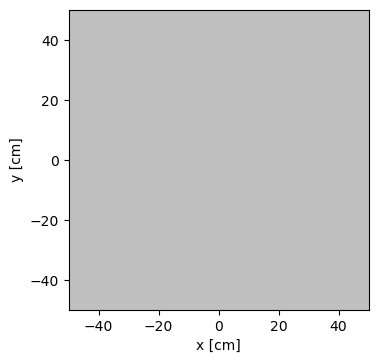

In [11]:
# Create a hexagonal lead assembly

lead_assembly = openmc.model.hexagonal_prism(edge_length=7*1.384, orientation='x')
la_cell = openmc.Cell(fill=lead, region=lead_assembly)
out_la_cell  = openmc.Cell(fill=lead, region=~lead_assembly)
lead_u = openmc.Universe(cells=[la_cell, out_la_cell])

lead_u.plot(origin = (0,0,0), pixels=(300, 300), width = (100.,100.), color_by = 'material',
            colors = mat_colours)

<Axes: xlabel='x [cm]', ylabel='y [cm]'>

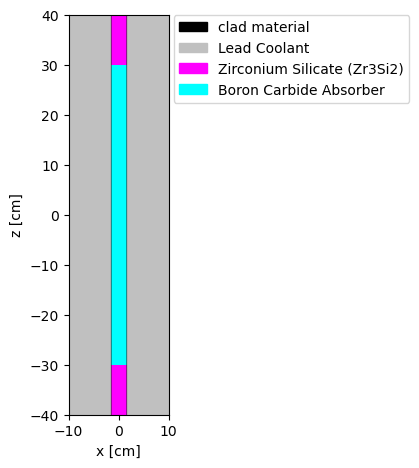

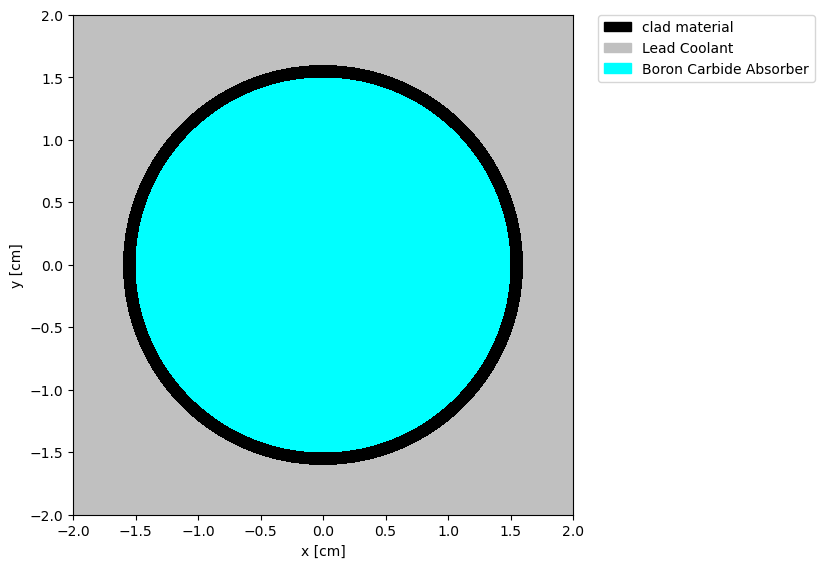

In [12]:
#control rod
control_rod_radius = openmc.ZCylinder(r=1.5)
control_rod_clad_radius = openmc.ZCylinder(r=1.6)
control_rod_bottom = openmc.ZPlane(z0 =-30)

control_rod_region = -control_rod_radius & -top_fuel & +control_rod_bottom 
control_rod_clad_region = -control_rod_clad_radius & +control_rod_radius & -top & +bottom 
control_rod_bottom_region = -control_rod_clad_radius & -control_rod_bottom & +bottom & +top_fuel

control_rod_coolant_region = +control_rod_clad_radius & -top & +bottom 

cr_cell = openmc.Cell(fill=b4c, region=control_rod_region)
cr_clad_cell = openmc.Cell(fill=t91, region=control_rod_clad_region)
cr_coolant_cell = openmc.Cell(fill=lead, region=control_rod_coolant_region)
cr_bottom_cell = openmc.Cell(fill=lead, region=control_rod_bottom_region)
bottom_reflector = openmc.Cell(name='Bottom Reflector', region = -control_rod_radius & +bottom & -control_rod_bottom, fill = reflector)
top_reflector = openmc.Cell(name='Top Reflector', region = -control_rod_radius & +top_fuel & -top, fill = reflector)

control_rod = openmc.Universe(cells=[cr_cell,cr_clad_cell,cr_coolant_cell,cr_bottom_cell, bottom_reflector, top_reflector])

control_rod.plot(origin = (0,0,0), pixels=(400, 400), width = (20,80), 
                 color_by = 'material', colors={t91:'black', lead:'silver',
                      reflector:'magenta', b4c:'cyan'}, basis='xz', legend=True)
control_rod.plot(origin = (0,0,0), pixels=(500, 500), width = (4,4), 
                 color_by = 'material',colors={t91:'black', lead:'silver',
                       b4c:'cyan'}, basis='xy', legend = True)

/home/nuclear1/anaconda3/envs/openmc_env/lib/python3.13/site-packages/openmc/model/funcs.py:124: FutureWarning: The hexagonal_prism(...) function has been replaced by the HexagonalPrism(...) class. Future versions of OpenMC will not accept hexagonal_prism.
  warn("The hexagonal_prism(...) function has been replaced by the "


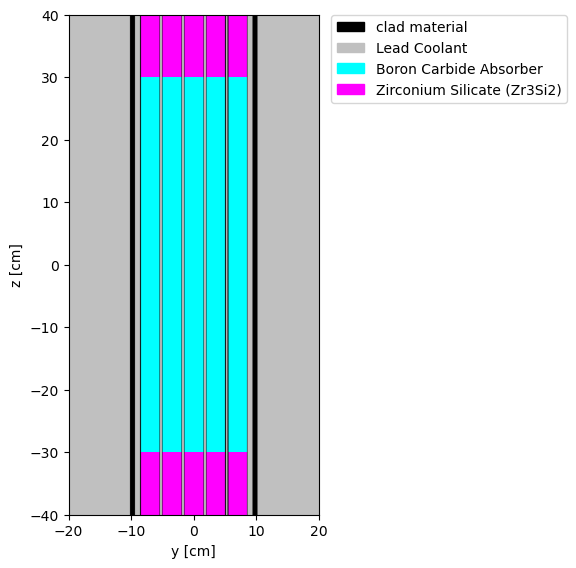

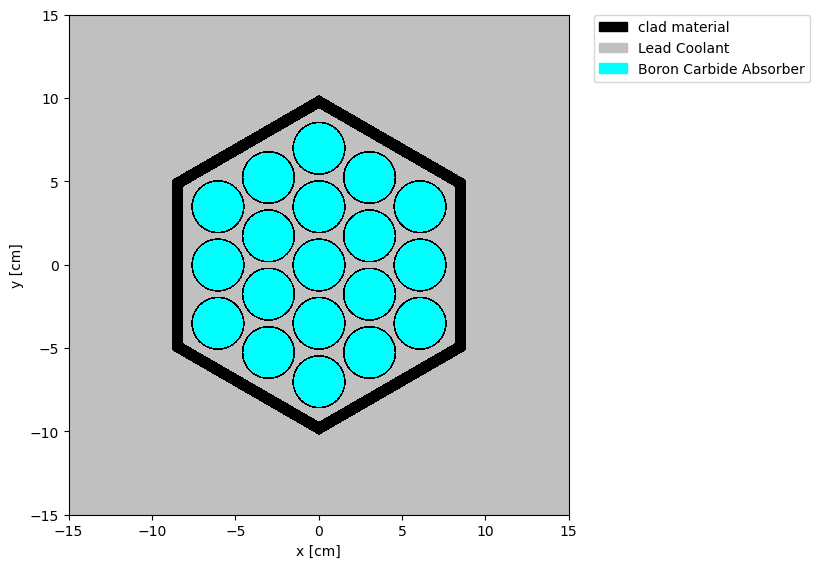

In [13]:
#control assembly
control_lat = openmc.HexLattice(name='control assembly')
control_lat.center = (0., 0.)
control_lat.pitch = (3.5,)
control_lat.orientation = 'y'
control_lat.outer = lead_univ

cring3= [control_rod]*12
cring2= [control_rod]*6
cring1= [control_rod]
control_lat.universes=[cring3,
                       cring2,
                       cring1]

control_lattice_boundary_in= openmc.model.hexagonal_prism(edge_length=9.4, orientation='y')
control_lattice_boundary_out= openmc.model.hexagonal_prism(edge_length=10.2, orientation='y')

control_wrapper_cell = openmc.Cell(fill=t91, 
                    region= ~control_lattice_boundary_in & control_lattice_boundary_out & 
                    -top & +bottom)
control_wrapper_cell_out = openmc.Cell(fill=lead, 
                    region= ~control_lattice_boundary_in & control_lattice_boundary_out & 
                    -bottom & +bottom)

control_cell = openmc.Cell(fill=control_lat, 
                    region= control_lattice_boundary_in & -top & +bottom)
control_surrounding = openmc.Cell(fill=lead, 
                    region= ~control_lattice_boundary_out & -top & +bottom)

control_u= openmc.Universe(cells=[control_cell,control_surrounding,
                                          control_wrapper_cell,control_wrapper_cell_out])

img1 = control_u.plot(origin = (0,0,0), pixels=(500, 500), width = (40,80), 
                          color_by = 'material', colors={t91:'black', lead:'silver',
                       b4c:'cyan',reflector:'magenta'}, basis='yz', legend=True)
img2 = control_u.plot(origin = (0,0,0), pixels=(500, 500), width = (30,30), 
                          color_by = 'material', colors={t91:'black', lead:'silver',
                       b4c:'cyan'}, basis='xy', legend=True)


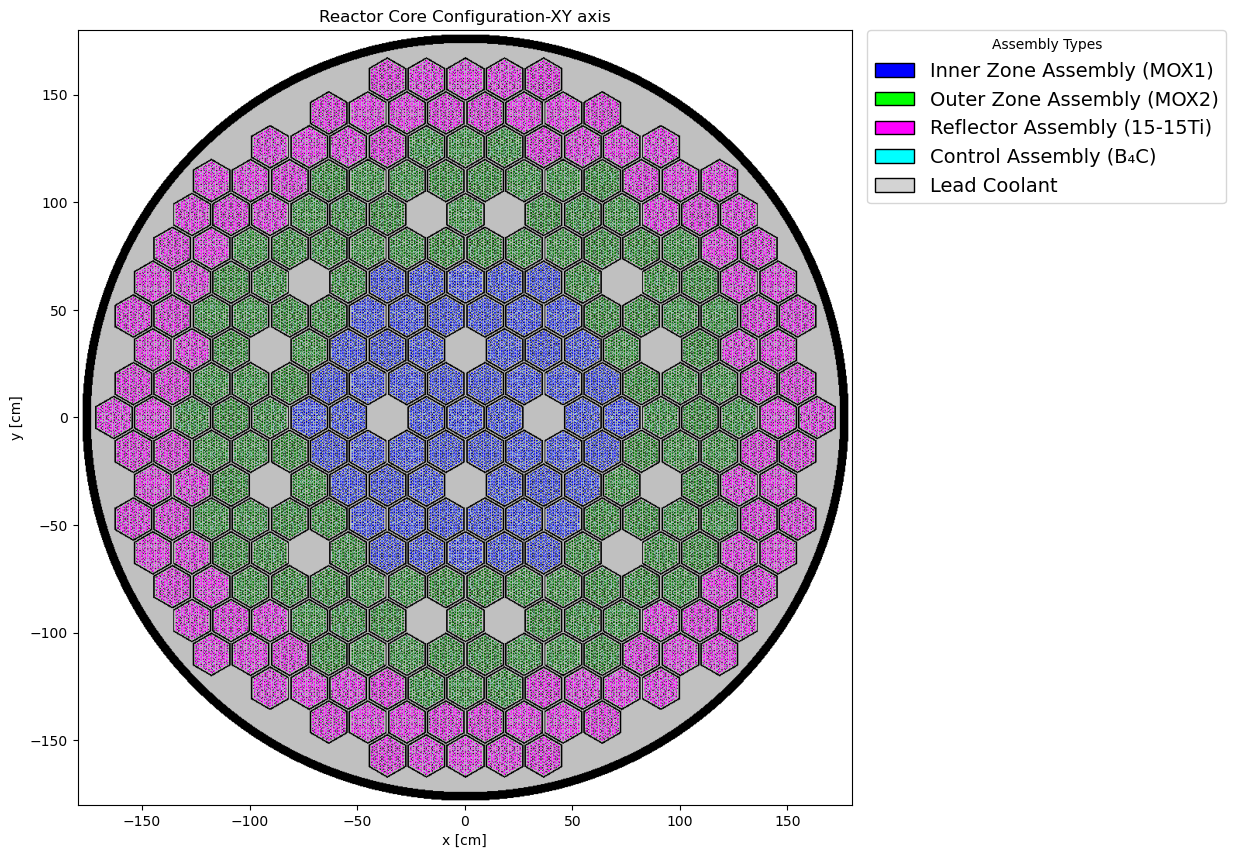

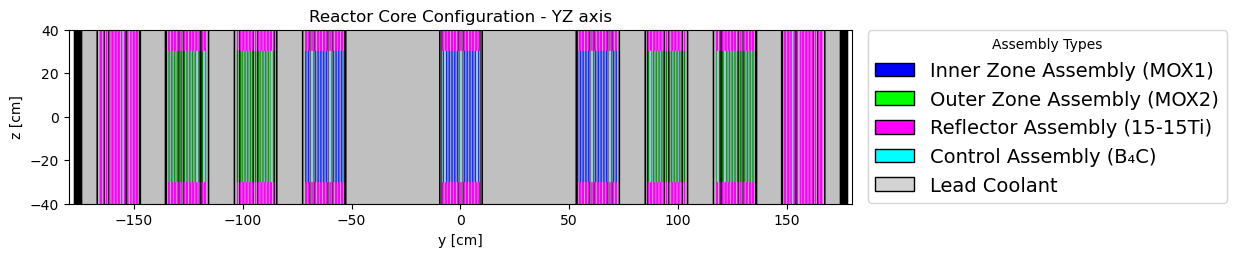

In [14]:
# Define the core lattice

core_lat = openmc.HexLattice(name='core')
core_lat.center = (0., 0.)
core_lat.pitch = (11*1.65,)
core_lat.outer = lead_univ
core_lat.orientation = 'x'

# Create rings of fuel universes that will fill the lattice

outer_ring = [lead_u, lead_u, lead_u, ba_u, ba_u, ba_u, ba_u, ba_u, lead_u, lead_u]*6

ring_9 = [ba_u]*9 + [lead_u] + [ba_u]*8 + [lead_u] + [ba_u]*17 + [lead_u] + [ba_u]*8 + [lead_u] + [ba_u]*8 

ring_8 = [ba_u, ba_u, ba_u, main_out_u, main_out_u, main_out_u, ba_u, ba_u]*6

ring_7 = [main_out_u, main_out_u, main_out_u, main_out_u, main_out_u, main_out_u, main_out_u]*6

ring_6 = [main_out_u, main_out_u, lead_u, main_out_u, lead_u, main_out_u]*6

ring_5 = [main_out_u, main_out_u, main_out_u, main_out_u, main_out_u]*6

ring_4 = [main_in_u]*24

ring_3 = [main_in_u]*18

ring_2 = [lead_u, main_in_u, main_in_u]*4

ring_1 = [main_in_u]*6

inner_ring = [main_in_u]

core_lat.universes = [outer_ring, ring_9, ring_8, ring_7, ring_6, ring_5, ring_4, ring_3, ring_2, ring_1, inner_ring]

# Create the prism that will contain the lattice
outer_core_surface = openmc.ZCylinder(r=174)
outer_vessel = openmc.ZCylinder(r=178, boundary_type='vacuum')

# Fill a cell with the lattice. This cell is filled with the lattice and contained within the prism.
core = openmc.Cell(fill=core_lat, region=-outer_core_surface & -top & +bottom)
vessel= openmc.Cell(fill=t91, region=-outer_vessel & +outer_core_surface & -top & +bottom)

# Create a universe that contains the lattice
main_u = openmc.Universe(cells=[core, vessel]) 

import matplotlib.patches as mpatches

img = main_u.plot(
    origin=(0, 0, 0),
    pixels=(1000, 1000),
    width=(360, 360),
    color_by='material',
    colors=mat_colours
)

# ---- Get current axis and figure ----
ax = plt.gca()
fig = plt.gcf()

# ---- Label and axis formatting ----
ax.set_xlim(-180, 180)
ax.set_ylim(-180, 180)
ax.set_xlabel('x [cm]')
ax.set_ylabel('y [cm]')
ax.set_title('Reactor Core Configuration-XY axis')

# ---- Define custom legend ----
legend_elements = [
    mpatches.Patch(facecolor='#0000FF', edgecolor='k', label='Inner Zone Assembly (MOX1)'),   # Blue
    mpatches.Patch(facecolor='#00FF00', edgecolor='k', label='Outer Zone Assembly (MOX2)'),   # Green
    mpatches.Patch(facecolor='#FF00FF', edgecolor='k', label='Reflector Assembly (15-15Ti)'), # Magenta
    mpatches.Patch(facecolor='#00FFFF', edgecolor='k', label='Control Assembly (B₄C)'),       # Cyan
    mpatches.Patch(facecolor='lightgray', edgecolor='k', label='Lead Coolant') # Gray
]

# ---- Add legend outside plot (right, top aligned) ----
ax.legend(
    handles=legend_elements,
    loc='upper left',
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0.,
    fontsize=14,
    title='Assembly Types'
)

# ---- Adjust layout ----
plt.tight_layout(pad=2.5)
plt.show()

img = main_u.plot(basis='yz',origin=(0, 0, 0),pixels=(1000, 1000), width=(360, 80), color_by='material', colors=mat_colours)

# ---- Get current axis and figure ----
ax = plt.gca()
fig = plt.gcf()

ax.set_title('Reactor Core Configuration - YZ axis')

# ---- Define custom legend ----
legend_elements = [
    mpatches.Patch(facecolor='#0000FF', edgecolor='k', label='Inner Zone Assembly (MOX1)'),   # Blue
    mpatches.Patch(facecolor='#00FF00', edgecolor='k', label='Outer Zone Assembly (MOX2)'),   # Green
    mpatches.Patch(facecolor='#FF00FF', edgecolor='k', label='Reflector Assembly (15-15Ti)'), # Magenta
    mpatches.Patch(facecolor='#00FFFF', edgecolor='k', label='Control Assembly (B₄C)'),       # Cyan
    mpatches.Patch(facecolor='lightgray', edgecolor='k', label='Lead Coolant') # Gray
]

# ---- Add legend outside plot (right, top aligned) ----
ax.legend(
    handles=legend_elements,
    loc='upper left',
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0.,
    fontsize=14,
    title='Assembly Types'
)

# ---- Adjust layout ----
plt.tight_layout(pad=2.5)
plt.show()

In [15]:
geometry = openmc.Geometry(main_u)
geometry.export_to_xml()

In [16]:
# OpenMC simulation parameters
batches = 100
inactive = 20
particles = 50000

In [17]:
# Instantiate a Settings object, set all runtime parameters, and export to XML
settings_file = openmc.Settings()
settings_file.temperature = {'method':'interpolation'}
settings_file.batches = batches
settings_file.inactive = inactive
settings_file.particles = particles
settings_file.energy_mode = 'continuous-energy'

# Create an initial uniform spatial source distribution over fissionable zones
bounds = [-170, -170, -30, 170, 170, 30]
uniform_dist = openmc.stats.Box(bounds[:3], bounds[3:], only_fissionable=True)
settings_file.source = openmc.Source(space=uniform_dist)



settings_file.export_to_xml()

/home/nuclear1/anaconda3/envs/openmc_env/lib/python3.13/site-packages/openmc/stats/multivariate.py:943: FutureWarning: The 'only_fissionable' has been deprecated. Use the 'constraints' argument when defining a source instead.
  warn("The 'only_fissionable' has been deprecated. Use the "
/home/nuclear1/anaconda3/envs/openmc_env/lib/python3.13/site-packages/openmc/source.py:658: FutureWarning: This class is deprecated in favor of 'IndependentSource'
  warnings.warn("This class is deprecated in favor of 'IndependentSource'", FutureWarning)


In [18]:
openmc.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [21]:
#volume calculation

import numpy as np
import math
openmc.config['cross_sections']='/home/nuclear1/Downloads/R_Depletion/Dep_6/cross_sections.xml'

MOX1.volume = math.pi * (0.45**2-0.20**2)  * 60 * 127 * 57
MOX2.volume = math.pi * (0.45**2-0.10**2)  * 60 * 127 * 114

# MOX1.volume = 221734.40
# MOX2.volume = 525339.95

chain = openmc.deplete.Chain.from_xml("/home/nuclear1/Downloads/R_Depletion/chain_casl_sfr.xml")
model = openmc.Model(geometry=geometry, settings=settings_file)
operator = openmc.deplete.CoupledOperator(model, "/home/nuclear1/Downloads/R_Depletion/chain_casl_sfr.xml")

power = 300 * 1e6

time_steps = [30] * 12
integrator = openmc.deplete.PredictorIntegrator(operator, time_steps, power, timestep_units='d')

In [22]:
integrator.integrate()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

 Reading B11 from
 /home/nuclear1/Downloads/R_Depletion/Dep_6/ENDFB-8.0-NNDC_B11.h5
 Maximum neutron transport energy: 20000000 eV for Np237
 Initializing source particles...

 ====================>     K EIGENVALUE SIMULATION     <====================

  Bat./Gen.      k            Average k
  =========   ========   ====================
        1/1    1.18096
        2/1    1.19830
        3/1    1.20290
        4/1    1.20518
        5/1    1.19486
        6/1    1.20598
        7/1    1.20246
        8/1    1.20725
        9/1    1.20246
       10/1    1.21749
       11/1    1.20857
       12/1    1.21442
       13/1    1.21229
       14/1    1.20865
       15/1    1.20473
       16/1    1.21192
       17/1    1.20441
       18/1    1.20342
       19/1    1.21266
       20/1    1.20663
       21/1    1.19680
       22/1    1.19986    1.19833 +/- 0.00153
       23/1    1.20880    1.20182 +/- 0.00360
       24/1    1.21531    1.20520 +/- 0.00422
       25/1    1.20246    1.20465 +/- 0

In [23]:
results = openmc.deplete.Results("./depletion_results.h5")

time, k = results.get_keff()
time /= (24 * 60 * 60)  # convert back to days from seconds
k

array([[1.20614303e+00, 3.25884947e-04],
       [1.20500959e+00, 3.27790066e-04],
       [1.20328256e+00, 3.73410450e-04],
       [1.20182667e+00, 3.41425015e-04],
       [1.20032719e+00, 3.58592461e-04],
       [1.19897587e+00, 3.09849158e-04],
       [1.19700239e+00, 3.22753436e-04],
       [1.19542515e+00, 3.31171380e-04],
       [1.19431037e+00, 3.44178967e-04],
       [1.19256941e+00, 2.92299446e-04],
       [1.19113925e+00, 3.78376440e-04],
       [1.19031646e+00, 3.36479766e-04],
       [1.18845619e+00, 3.28358637e-04]])

<>:8: SyntaxWarning: invalid escape sequence '\p'
<>:8: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_21087/1797246180.py:8: SyntaxWarning: invalid escape sequence '\p'
  plt.ylabel("$k_{eff}\pm \sigma$");


[1.20614303 1.20500959 1.20328256 1.20182667 1.20032719 1.19897587
 1.19700239 1.19542515 1.19431037 1.19256941 1.19113925 1.19031646
 1.18845619]


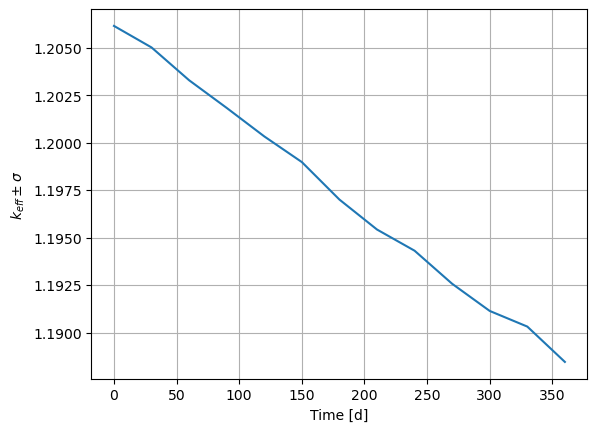

In [24]:
k_eff = k[:, 0]

k_eff= np.array(k_eff).reshape((-1, 1))
k_eff = k_eff.flatten()
print(k_eff)
plt.plot(time, k[:, 0])
plt.xlabel("Time [d]")
plt.ylabel("$k_{eff}\pm \sigma$");
plt.grid(True)

In [25]:
_, u235_in = results.get_atoms("4","U235")
_, u235_out = results.get_atoms("5","U235")
u235 = u235_in + u235_out
print(u235)

[3.40737930e+25 3.37851568e+25 3.34980940e+25 3.32124691e+25
 3.29284200e+25 3.26459207e+25 3.23651803e+25 3.20861979e+25
 3.18087247e+25 3.15329321e+25 3.12586019e+25 3.09860181e+25
 3.07151695e+25]


In [26]:
_, u234_in = results.get_atoms("4","U234")
_, u234_out = results.get_atoms("5","U234")
u234 = u234_in + u234_out
print(u234)

[3.04556359e+23 3.33965212e+23 3.64062357e+23 3.94892304e+23
 4.26469679e+23 4.58814492e+23 4.91948533e+23 5.25879804e+23
 5.60614885e+23 5.96158158e+23 6.32516289e+23 6.69692442e+23
 7.07676268e+23]


In [27]:
_, u236_in = results.get_atoms("4","U236")
_, u236_out = results.get_atoms("5","U236")
u236 = u236_in + u236_out
print(u236)

[1.56074338e+23 2.32540027e+23 3.08568555e+23 3.84153005e+23
 4.59314914e+23 5.34031297e+23 6.08229277e+23 6.81902929e+23
 7.55140931e+23 8.27879209e+23 9.00213533e+23 9.72045177e+23
 1.04335728e+24]


In [28]:
_, u238_in = results.get_atoms("4","U238")
_, u238_out = results.get_atoms("5","U238")
u238 = u238_in + u238_out
print(u238)

[1.34232629e+28 1.34080235e+28 1.33927469e+28 1.33774337e+28
 1.33620813e+28 1.33466915e+28 1.33312791e+28 1.33158362e+28
 1.33003597e+28 1.32848474e+28 1.32692919e+28 1.32537146e+28
 1.32380977e+28]


In [29]:
_, pu238_in = results.get_atoms("4","Pu238")
_, pu238_out = results.get_atoms("5","Pu238")
pu238 = pu238_in + pu238_out
print(pu238)

[4.60604641e+25 4.71000643e+25 4.83384582e+25 4.96190856e+25
 5.09356918e+25 5.22827939e+25 5.36534577e+25 5.50426345e+25
 5.64471230e+25 5.78626870e+25 5.92876089e+25 6.07173381e+25
 6.21494992e+25]


In [30]:
_, pu239_in = results.get_atoms("4","Pu239")
_, pu239_out = results.get_atoms("5","Pu239")
pu239 = pu239_in + pu239_out
print(pu239)

[3.03538459e+27 3.02353354e+27 3.01325643e+27 3.00302389e+27
 2.99283721e+27 2.98269243e+27 2.97258623e+27 2.96252182e+27
 2.95249950e+27 2.94252142e+27 2.93259074e+27 2.92270051e+27
 2.91286102e+27]


In [31]:
_, pu240_in = results.get_atoms("4","Pu240")
_, pu240_out = results.get_atoms("5","Pu240")
pu240 = pu240_in + pu240_out
print(pu240)

[1.16072370e+27 1.16258457e+27 1.16443176e+27 1.16626965e+27
 1.16809543e+27 1.16991540e+27 1.17171935e+27 1.17350736e+27
 1.17528720e+27 1.17705683e+27 1.17881686e+27 1.18056320e+27
 1.18229533e+27]


In [32]:
_, pu241_in = results.get_atoms("4","Pu241")
_, pu241_out = results.get_atoms("5","Pu241")
pu241 = pu241_in + pu241_out
print(pu241)

[1.79635810e+26 1.79116219e+26 1.78609276e+26 1.78113384e+26
 1.77631966e+26 1.77160782e+26 1.76700494e+26 1.76255042e+26
 1.75818195e+26 1.75392842e+26 1.74981096e+26 1.74577350e+26
 1.74184979e+26]


In [33]:
_, pu242_in = results.get_atoms("4","Pu242")
_, pu242_out = results.get_atoms("5","Pu242")
pu242 = pu242_in + pu242_out
print(pu242)

[1.84241857e+26 1.84197016e+26 1.84154925e+26 1.84111608e+26
 1.84067633e+26 1.84023644e+26 1.83978239e+26 1.83931201e+26
 1.83884167e+26 1.83836472e+26 1.83788232e+26 1.83739892e+26
 1.83690850e+26]


In [34]:
_, xe135_in = results.get_atoms("4","Xe135")
_, xe135_out = results.get_atoms("5","Xe135")
xe135 = xe135_in + xe135_out
print(xe135)

[0.00000000e+00 3.33246568e+22 3.33375797e+22 3.33365060e+22
 3.33354693e+22 3.33345181e+22 3.33331544e+22 3.33319069e+22
 3.33308319e+22 3.33293699e+22 3.33283016e+22 3.33267942e+22
 3.33253510e+22]


In [35]:
_, sm149_in = results.get_atoms("4","Sm149")
_, sm149_out = results.get_atoms("5","Sm149")
sm149 = sm149_in + sm149_out
print(sm149)

[0.00000000e+00 2.77911554e+23 5.90207753e+23 9.02561959e+23
 1.21495415e+24 1.52737681e+24 1.83984202e+24 2.15234937e+24
 2.46488793e+24 2.77747137e+24 3.09008810e+24 3.40274815e+24
 3.71545369e+24]


[2.57793841e+26 2.56109088e+26 2.54446099e+26 2.52789994e+26
 2.51138827e+26 2.49492677e+26 2.47853675e+26 2.46220802e+26
 2.44593601e+26 2.42972876e+26 2.41357519e+26 2.39748931e+26
 2.38146755e+26]
[1.19085072e+26 1.18900785e+26 1.18712725e+26 1.18521493e+26
 1.18326750e+26 1.18128465e+26 1.17927282e+26 1.17723503e+26
 1.17516665e+26 1.17306893e+26 1.17094187e+26 1.16879179e+26
 1.16661433e+26]
[5.36831658e+25 5.36052398e+25 5.35305925e+25 5.34564189e+25
 5.33823768e+25 5.33081431e+25 5.32350497e+25 5.31625479e+25
 5.30899881e+25 5.30179370e+25 5.29458876e+25 5.28736239e+25
 5.28017963e+25]
[1.34207910e+23 1.32248045e+23 1.30311155e+23 1.28399354e+23
 1.26509874e+23 1.24643913e+23 1.22801862e+23 1.20982492e+23
 1.19186565e+23 1.17413454e+23 1.15662444e+23 1.13934391e+23
 1.12228488e+23]
[2.27662883e+25 2.29262232e+25 2.30864635e+25 2.32459027e+25
 2.34047386e+25 2.35631743e+25 2.37206765e+25 2.38773842e+25
 2.40335900e+25 2.41889001e+25 2.43438178e+25 2.44976613e+25
 2.46507695e+25]


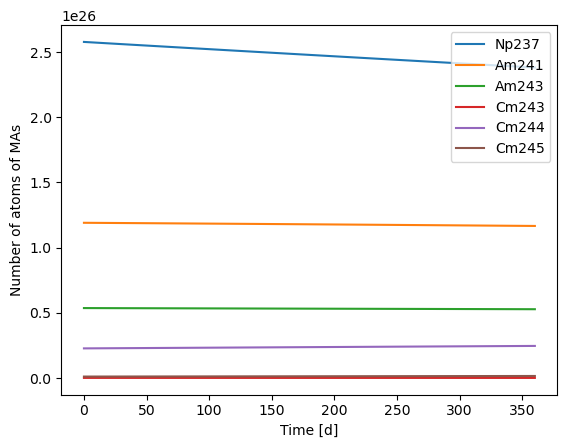

In [36]:
_, np237_in = results.get_atoms("4","Np237")
_, am241_in = results.get_atoms("4","Am241")
_, am243_in = results.get_atoms("4", "Am243")
_, cm243_in = results.get_atoms("4","Cm243")
_, cm244_in = results.get_atoms("4","Cm244")
_, cm245_in = results.get_atoms("4", "Cm245")
_, np237_out = results.get_atoms("5","Np237")
_, am241_out = results.get_atoms("5","Am241")
_, am243_out = results.get_atoms("5", "Am243")
_, cm243_out = results.get_atoms("5","Cm243")
_, cm244_out = results.get_atoms("5","Cm244")
_, cm245_out = results.get_atoms("5", "Cm245")

np237 = np237_in + np237_out
am241 = am241_in + am241_out
am243 = am243_in + am243_out
cm243 = cm243_in + cm243_out
cm244 = cm244_in + cm244_out
cm245 = cm245_in + cm245_out

print(np237)
print(am241)
print(am243)
print(cm243)
print(cm244)
print(cm245)

plt.plot(time, np237, label="Np237", )

plt.plot(time, am241, label="Am241")

plt.plot(time, am243, label="Am243")


plt.plot(time, cm243, label="Cm243")

plt.plot(time, cm244, label="Cm244")


plt.plot(time, cm245, label="Cm245")


plt.xlabel("Time [d]")
plt.ylabel("Number of atoms of MAs");
plt.legend()

In [37]:
fuel_loading = operator.heavy_metal
print('The core power is', power, 'W')
print('\nThe time steps are: \n', time)
print('\nThe initial heavy metal loading is', fuel_loading, 'g')

burnup = (power * 10**(-6))*time/(fuel_loading * 10**(-3))
print('\nThe burnup steps are:\n', burnup)

print('\nThe power density is', (power * 10**(-6))/(fuel_loading/1000), 'MW/kg')

The core power is 300000000.0 W

The time steps are: 
 [  0.  30.  60.  90. 120. 150. 180. 210. 240. 270. 300. 330. 360.]

The initial heavy metal loading is 7331922.605035927 g

The burnup steps are:
 [ 0.          1.22750887  2.45501773  3.6825266   4.91003546  6.13754433
  7.36505319  8.59256206  9.82007093 11.04757979 12.27508866 13.50259752
 14.73010639]

The power density is 0.040916962188600456 MW/kg
